# Flow-prior analysis — VCTK words (nfv8)

Companion to `vae_latent_analysis.ipynb`. That notebook studies the *latent space* (the aggregate posterior). This one studies the **normalizing-flow prior** trained on top of it — the `RealNVP` from `src/prior_model.py` that replaces the plain $\mathcal{N}(0, I)$ when we sample the VAE unconditionally.

```
--prior_config_path prior_configs/v1.yaml \
--prior_checkpoint  logs/nfv8_prior/version_0/checkpoints/epoch=19-step=2000.ckpt
```

A prior is only useful if it **matches the aggregate posterior** — the distribution of the VAE's encoded latents. So the analysis is a distribution-fit check, from three angles:

1. **Likelihood** — how well the flow scores held-out latents, vs. the $\mathcal{N}(0, I)$ baseline the flow is supposed to improve on. This is exactly `prior_validation_loss` (mean negative log-likelihood).
2. **Base space** — the flow maps data $z$ to a base variable $u = T(z)$ that *should* be $\mathcal{N}(0, I)$. If the fit is good, $u$ passes Gaussianity checks; where it deviates tells you what the flow failed to straighten.
3. **Samples** — draw $z \sim \text{prior}$ and compare against real latents (moments, PCA overlay, 2-D maps, per-dim marginals). This is what actually feeds the decoder at generation time.

> **Which latents?** The prior was trained on `audio_train_in_latent_space_nfv8`; we use those as the **train** set (the flow saw all of them). The held-out set is the **dedicated val dump `audio_val_in_latent_space_nfv8`** — latents from the VAE's own validation clips, encoded through the same nfv8 VAE, and never seen by the flow. **These are a different latent set from the `audio_val_in_latent_space` used in `vae_latent_analysis.ipynb`** (that dump is from a different, non-nfv8 VAE) — this notebook must stay on the `nfv8` latents the prior was actually fit on, or every number is meaningless."

## 0 · Setup

In [2]:
import warnings
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy import stats

from src.ds_utils import load_audio_tensor
from src.prior_model import Prior
from src.train_prior import PriorTrainingConfig

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import yaml
from cattrs import structure

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- config (matches the CLI invocation) ----
PRIOR_CONFIG_PATH = "prior_configs/v1.yaml"
PRIOR_CHECKPOINT  = "logs/nfv8_prior/version_0/checkpoints/epoch=19-step=2000.ckpt"
# dedicated held-out val latents (nfv8 VAE), never seen by the flow
VAL_LATENTS_PATH  = "/media/Data/jp_dir/sounds/vctk_words_v2/audio_val_in_latent_space_nfv8"
DEVICE       = "cuda:1" if torch.cuda.is_available() else "cpu"
RANDOM_STATE = 0
rng = np.random.default_rng(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})
print("device:", DEVICE)

device: cuda:1


### Load the prior config, checkpoint, and its train / held-out latents

We read `prior_configs/v1.yaml` through the same `PriorTrainingConfig` the trainer uses, so `LATENT_DIM`, the train-dataset path, and the model hyperparameters all come straight from the config rather than being hard-coded. The **train** latents are the full `train_dataset_path` (all seen by the flow); the **held-out** latents are the dedicated `VAL_LATENTS_PATH` dump.

In [3]:
with open(PRIOR_CONFIG_PATH) as f:
    cfg = structure(yaml.safe_load(f), PriorTrainingConfig)

LATENT_DIM = cfg.model.latent_size
print(f"experiment={cfg.experiment_name}  latent_size={LATENT_DIM}  layers={cfg.model.layers}")
print(f"dataset: {cfg.train_dataset_path}")

# load the model exactly as generate.py does
from attrs import asdict
prior = Prior.load_from_checkpoint(
    PRIOR_CHECKPOINT, **asdict(cfg.model), map_location=DEVICE, weights_only=False
)
prior.eval().to(DEVICE)
print("prior loaded:", type(prior.flow).__name__)

experiment=nfv8_prior  latent_size=256  layers=10
dataset: /media/Data/jp_dir/sounds/vctk_words_v2/audio_train_in_latent_space_nfv8
prior loaded: RealNVP


In [4]:
# train = full nfv8 train latents (flow saw all of these);
# held-out = dedicated val dump (flow never saw these)
def _load_flat(path):
    d = load_audio_tensor(path).data.float()
    d = d.reshape(d.shape[0], -1)          # length-1 latent -> (N, C)
    assert d.shape[1] == LATENT_DIM, (path, d.shape, LATENT_DIM)
    return d

Z_train = _load_flat(cfg.train_dataset_path)
Z_val   = _load_flat(VAL_LATENTS_PATH)

print(f"train {len(Z_train)} (seen)  |  held-out {len(Z_val)} (unseen)")
Zt = Z_train.cpu().numpy()
Zv = Z_val.cpu().numpy()

train 225748 (seen)  |  held-out 24872 (unseen)


In [5]:
# --- flow helpers (zuko RealNVP) --------------------------------------------
# prior.flow() -> NormalizingFlow with .log_prob(x), .sample((n,)), .base, .transform
# transform maps DATA -> BASE:  u = T(z),  and  log_prob(z) = base.log_prob(u) + ladj
@torch.inference_mode()
def flow_log_prob(Z, batch=4096):
    """Per-sample log p(z) under the flow (numpy in -> numpy out)."""
    out = []
    for i in range(0, len(Z), batch):
        x = torch.as_tensor(Z[i:i+batch], dtype=torch.float32, device=DEVICE)
        out.append(prior.flow().log_prob(x).cpu().numpy())
    return np.concatenate(out)

@torch.inference_mode()
def flow_to_base(Z, batch=4096):
    """Map data z to the base variable u = T(z); should be ~ N(0, I) if well fit."""
    out = []
    for i in range(0, len(Z), batch):
        x = torch.as_tensor(Z[i:i+batch], dtype=torch.float32, device=DEVICE)
        out.append(prior.flow().transform(x).cpu().numpy())
    return np.concatenate(out)

@torch.inference_mode()
def flow_sample(n, batch=4096):
    """Draw n samples z ~ prior (numpy out)."""
    out = []
    while sum(len(o) for o in out) < n:
        k = min(batch, n - sum(len(o) for o in out))
        out.append(prior.flow().sample((k,)).cpu().numpy())
    return np.concatenate(out)[:n]

def gaussian_log_prob(Z, mu, cov_diag):
    """Per-sample log N(z; mu, diag(cov)) baseline — the diagonal Gaussian MLE fit."""
    d = Z.shape[1]
    var = np.clip(cov_diag, 1e-12, None)
    return -0.5 * (((Z - mu) ** 2 / var).sum(1) + np.log(2 * np.pi * var).sum())

def scatter2d(XY, cats, title, ax=None, s=8):
    ax = ax or plt.gca()
    cats = np.asarray(cats)
    for c, col in [("real", "#1f77b4"), ("prior", "#d62728")]:
        m = cats == c
        ax.scatter(XY[m, 0], XY[m, 1], s=s, alpha=0.4, linewidths=0, color=col, label=c)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(markerscale=2, frameon=False)
    return ax

torch.manual_seed(RANDOM_STATE)   # make flow_sample reproducible across reruns

## 1 · Likelihood — does the flow beat $\mathcal{N}(0, I)$?

The flow is trained to minimise mean negative log-likelihood (`Prior.forward` = `-flow().log_prob(x).mean()`). Two things to check:

* **Generalisation.** Held-out NLL should be close to train NLL. A large gap means the flow memorised the training latents.
* **Was it worth it?** Compare against two baselines that need no flow at all: the standard $\mathcal{N}(0, I)$ (what the VAE prior *is*), and a diagonal Gaussian fitted to the training latents (the best you can do with independent per-dim Gaussians). The flow earns its keep only if it scores held-out data **higher** than both — i.e. it captures cross-dimension structure a diagonal Gaussian can't.

Log-likelihoods are reported as **nats/dim** (divided by `LATENT_DIM`) so the numbers are comparable regardless of dimensionality.

In [6]:
D = LATENT_DIM

ll_train = flow_log_prob(Zt)
ll_val   = flow_log_prob(Zv)

# baselines fitted on TRAIN, evaluated on held-out
mu_t, var_t = Zt.mean(0), Zt.var(0)
ll_std_val  = gaussian_log_prob(Zv, np.zeros(D), np.ones(D))    # N(0, I)
ll_diag_val = gaussian_log_prob(Zv, mu_t, var_t)               # diagonal-Gaussian MLE

print("mean log-likelihood (nats/dim, higher = better):")
print(f"  flow   — train      {ll_train.mean()/D:+.4f}")
print(f"  flow   — held-out   {ll_val.mean()/D:+.4f}")
print(f"  N(0,I) — held-out   {ll_std_val.mean()/D:+.4f}")
print(f"  diag N — held-out   {ll_diag_val.mean()/D:+.4f}")
print(f"\n  train/held-out NLL gap: {(ll_train.mean()-ll_val.mean())/D:+.4f} nats/dim"
      "  (large => overfit)")
print(f"  flow improvement over N(0,I):  {(ll_val.mean()-ll_std_val.mean())/D:+.4f} nats/dim")
print(f"  flow improvement over diag-N:  {(ll_val.mean()-ll_diag_val.mean())/D:+.4f} nats/dim")

mean log-likelihood (nats/dim, higher = better):
  flow   — train      -0.9812
  flow   — held-out   -0.9811
  N(0,I) — held-out   -1.3952
  diag N — held-out   -1.3598

  train/held-out NLL gap: -0.0001 nats/dim  (large => overfit)
  flow improvement over N(0,I):  +0.4141 nats/dim
  flow improvement over diag-N:  +0.3787 nats/dim


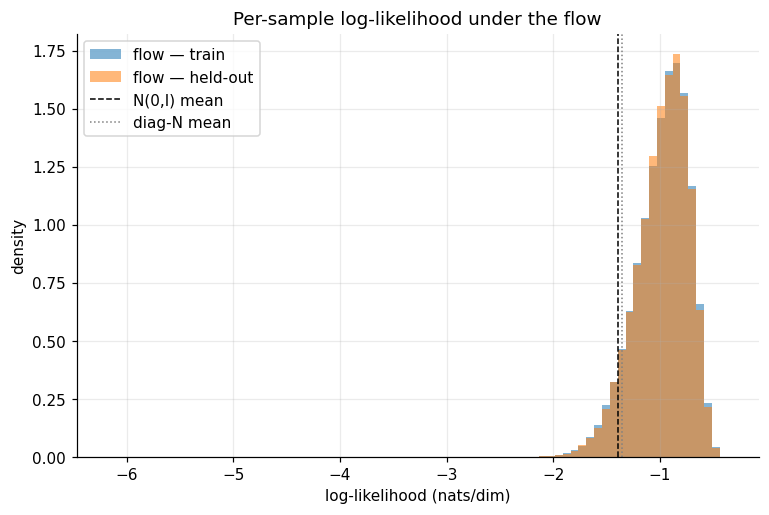

In [7]:
plt.figure()
bins = np.linspace(min(ll_train.min(), ll_val.min())/D,
                   max(ll_train.max(), ll_val.max())/D, 80)
plt.hist(ll_train/D, bins=bins, density=True, alpha=0.55, label="flow — train")
plt.hist(ll_val/D,   bins=bins, density=True, alpha=0.55, label="flow — held-out")
plt.axvline(ll_std_val.mean()/D, color="k", ls="--", lw=1, label="N(0,I) mean")
plt.axvline(ll_diag_val.mean()/D, color="gray", ls=":", lw=1, label="diag-N mean")
plt.xlabel("log-likelihood (nats/dim)"); plt.ylabel("density")
plt.title("Per-sample log-likelihood under the flow"); plt.legend(); plt.show()

## 2 · Base space — is $u = T(z)$ really $\mathcal{N}(0, I)$?

The flow is a bijection $z \leftrightarrow u$ with $u$ meant to be standard normal. Pushing the **held-out** latents forward through the transform, $u = T(z)$, gives the most direct fit diagnostic: if the flow fits, `u` is indistinguishable from $\mathcal{N}(0, I)$. Where it isn't tells you what structure the flow left on the table.

* **Marginal moments** — each $u_j$ should have mean 0, std 1, ~zero skew, ~zero excess kurtosis.
* **Whitening** — the base covariance should be $\approx I$: near-zero off-diagonal correlations (the flow's job is to remove the cross-dim correlations §1's diagonal baseline can't).
* **Normality** — a Q–Q plot of the pooled $u$ against the normal quantiles; heavy tails or curvature show mismatch.

base-space u = T(z_heldout): (24872, 256)
target: mean 0 | std 1 | skew 0 | excess-kurtosis 0
  mean      : avg +0.012   |max| 0.607
  std       : avg +0.942   range [0.781, 1.085]
  skew      : avg +0.000  |max| 0.116
  exc. kurt : avg +0.145  |max| 0.301


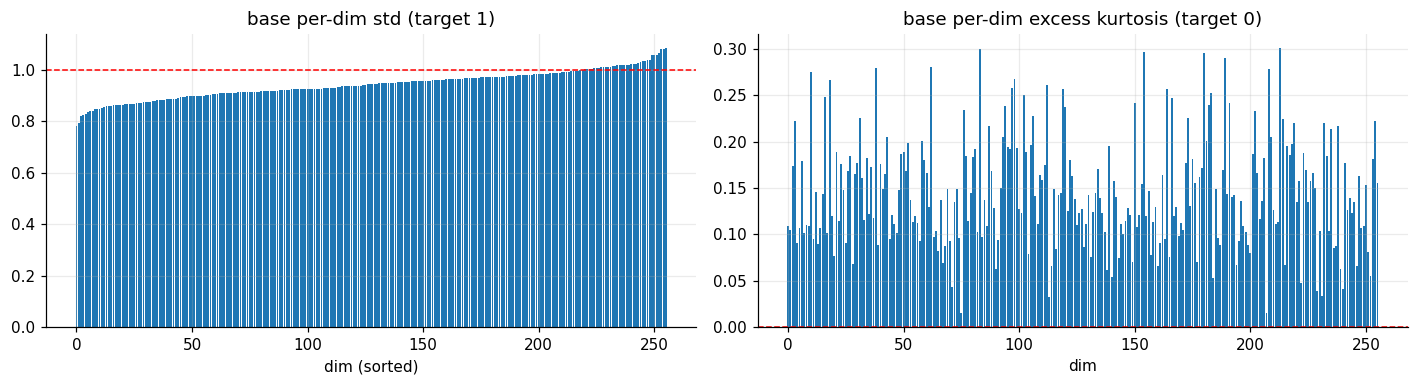

In [8]:
U = flow_to_base(Zv)     # held-out latents in base space
print("base-space u = T(z_heldout):", U.shape)

m, s = U.mean(0), U.std(0)
sk = stats.skew(U, axis=0)
ku = stats.kurtosis(U, axis=0)   # excess kurtosis (0 for normal)
print("target: mean 0 | std 1 | skew 0 | excess-kurtosis 0")
print(f"  mean      : avg {m.mean():+.3f}   |max| {np.abs(m).max():.3f}")
print(f"  std       : avg {s.mean():+.3f}   range [{s.min():.3f}, {s.max():.3f}]")
print(f"  skew      : avg {sk.mean():+.3f}  |max| {np.abs(sk).max():.3f}")
print(f"  exc. kurt : avg {ku.mean():+.3f}  |max| {np.abs(ku).max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].bar(range(D), np.sort(s)); ax[0].axhline(1, color="r", ls="--", lw=1)
ax[0].set_title("base per-dim std (target 1)"); ax[0].set_xlabel("dim (sorted)")
ax[1].bar(range(D), ku[np.argsort(s)]); ax[1].axhline(0, color="r", ls="--", lw=1)
ax[1].set_title("base per-dim excess kurtosis (target 0)"); ax[1].set_xlabel("dim")
plt.tight_layout(); plt.show()

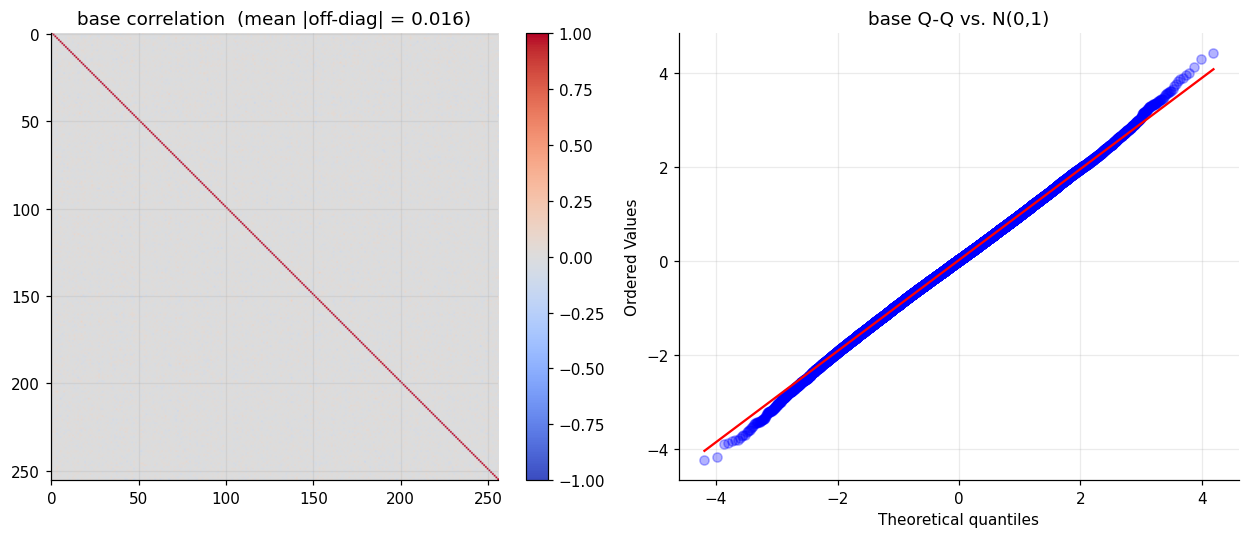

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# whitening: base covariance should be ~ I
C = np.corrcoef(U, rowvar=False)
im = ax[0].imshow(C, vmin=-1, vmax=1, cmap="coolwarm")
fig.colorbar(im, ax=ax[0], fraction=0.046)
off = C[~np.eye(D, dtype=bool)]
ax[0].set_title(f"base correlation  (mean |off-diag| = {np.abs(off).mean():.3f})")

# normality: pooled Q-Q against N(0,1)
sub = U.ravel()
sub = sub[rng.choice(len(sub), min(len(sub), 50000), replace=False)]
stats.probplot(sub, dist="norm", plot=ax[1])
ax[1].set_title("base Q-Q vs. N(0,1)"); ax[1].get_lines()[0].set_alpha(0.3)
plt.tight_layout(); plt.show()

## 3 · Samples — prior draws vs. real latents

The inverse direction: draw $z \sim \text{prior}$ and compare against real (held-out) latents. This is what actually reaches the decoder when we generate, so a mismatch here is a mismatch you can *hear*.

* **Moments** — per-dim mean and std of samples should track the real latents' (the aggregate posterior).
* **PCA overlay** — project both onto the real latents' principal axes; the sample cloud should sit on top of the real cloud in the leading components.
* **Per-dim marginals** — histograms for a few dims; the flow can match a diagonal Gaussian's marginals *and still* get the joint wrong, but marginal mismatch is an immediate red flag.

prior samples: (24872, 256)
per-dim mean : corr(real, prior) = 0.873   max|Δ| = 0.432
per-dim std  : corr(real, prior) = 0.898   max|Δ| = 0.362


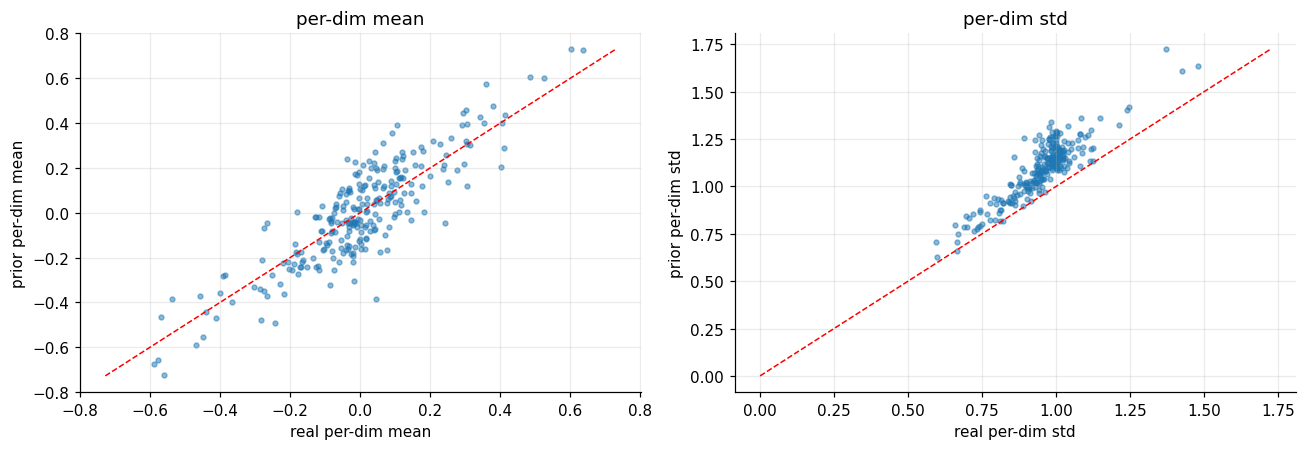

In [10]:
Zs = flow_sample(len(Zv))          # match held-out count
print("prior samples:", Zs.shape)

mr, sr = Zv.mean(0), Zv.std(0)
ms, ss = Zs.mean(0), Zs.std(0)
print(f"per-dim mean : corr(real, prior) = {np.corrcoef(mr, ms)[0,1]:.3f}"
      f"   max|Δ| = {np.abs(mr-ms).max():.3f}")
print(f"per-dim std  : corr(real, prior) = {np.corrcoef(sr, ss)[0,1]:.3f}"
      f"   max|Δ| = {np.abs(sr-ss).max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].scatter(mr, ms, s=10, alpha=0.5); lim = np.abs(np.r_[mr, ms]).max()
ax[0].plot([-lim, lim], [-lim, lim], "r--", lw=1)
ax[0].set_xlabel("real per-dim mean"); ax[0].set_ylabel("prior per-dim mean")
ax[0].set_title("per-dim mean")
ax[1].scatter(sr, ss, s=10, alpha=0.5); hi = np.r_[sr, ss].max()
ax[1].plot([0, hi], [0, hi], "r--", lw=1)
ax[1].set_xlabel("real per-dim std"); ax[1].set_ylabel("prior per-dim std")
ax[1].set_title("per-dim std")
plt.tight_layout(); plt.show()

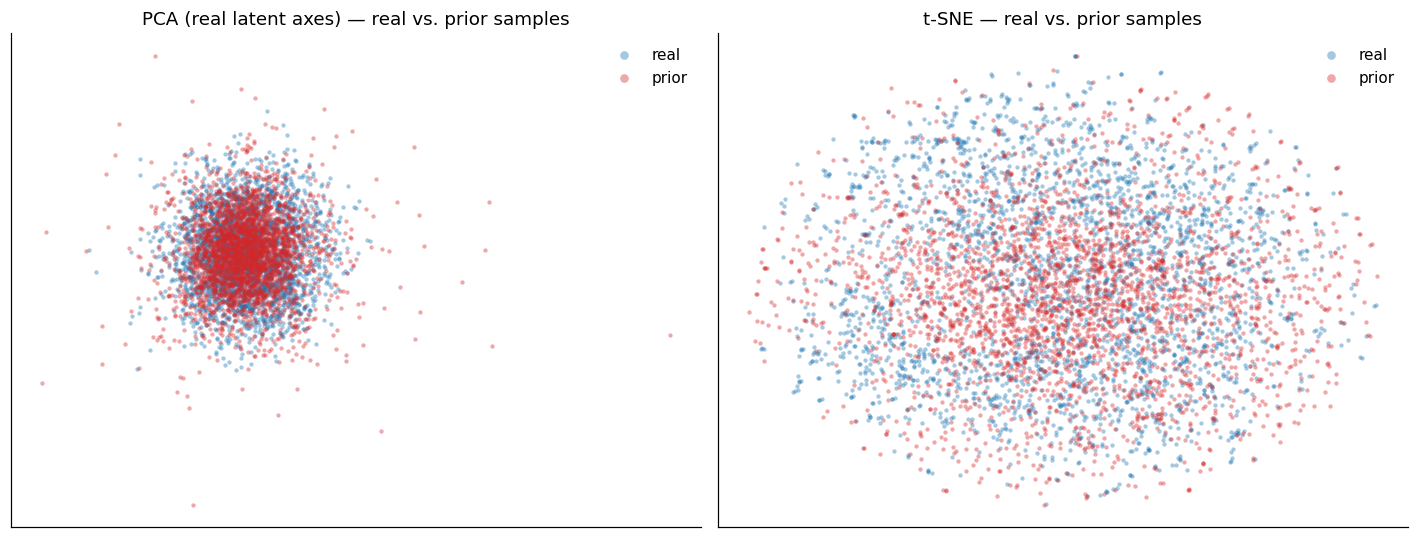

In [11]:
# fit PCA on REAL latents, project both -> shared axes
pca = PCA(2, random_state=RANDOM_STATE).fit(Zv)
n = min(3000, len(Zv), len(Zs))
ir = rng.choice(len(Zv), n, replace=False); is_ = rng.choice(len(Zs), n, replace=False)
XY  = np.vstack([pca.transform(Zv[ir]), pca.transform(Zs[is_])])
lab = np.array(["real"] * n + ["prior"] * n)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
scatter2d(XY, lab, "PCA (real latent axes) — real vs. prior samples", ax=ax[0])
# t-SNE on the joint set for a non-linear view
tsne = TSNE(2, init="pca", perplexity=30, random_state=RANDOM_STATE).fit_transform(
    np.vstack([Zv[ir], Zs[is_]]))
scatter2d(tsne, lab, "t-SNE — real vs. prior samples", ax=ax[1])
plt.tight_layout(); plt.show()

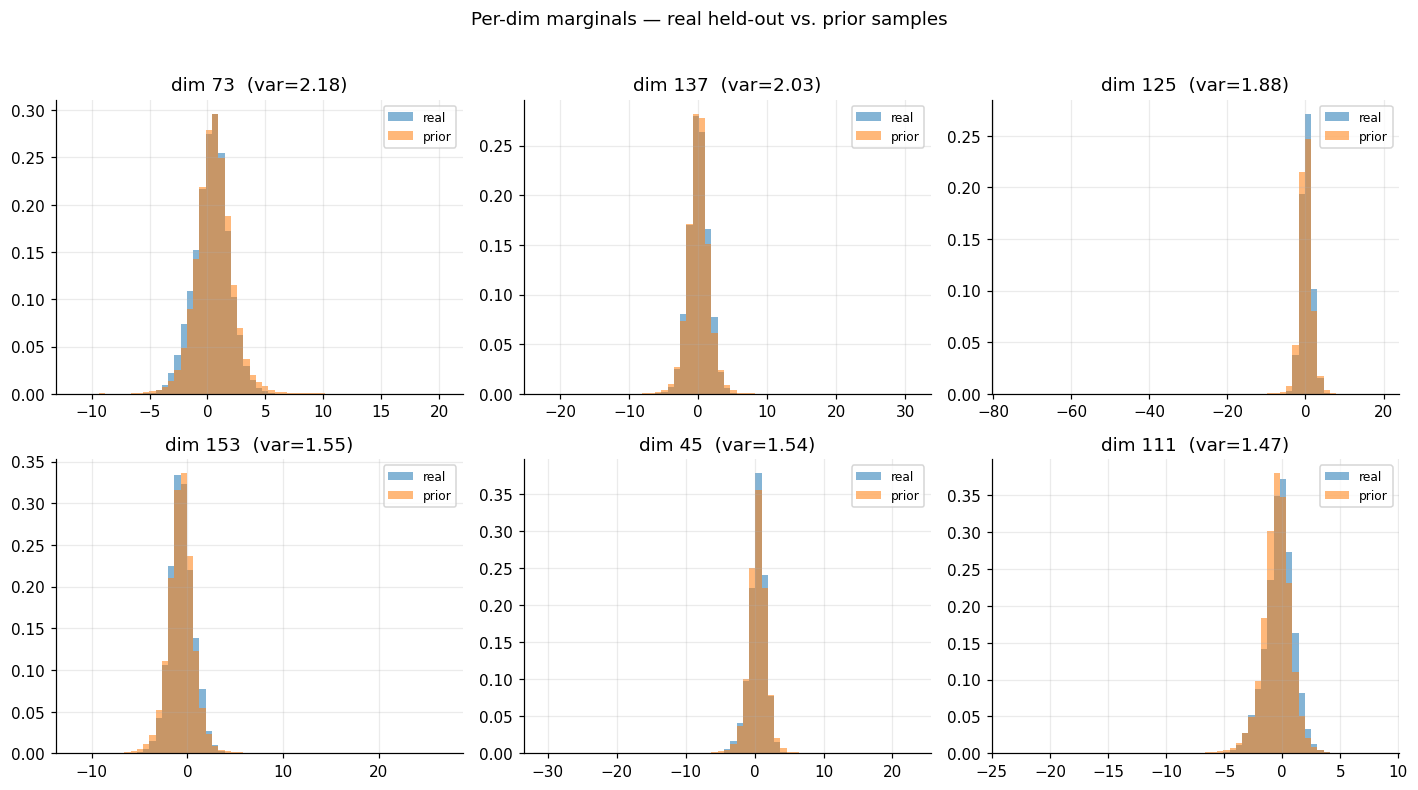

In [12]:
# per-dim marginals for the highest-variance real dims (where mismatch matters most)
top = np.argsort(Zv.var(0))[::-1][:6]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for d, ax in zip(top, axes.ravel()):
    lo = min(Zv[:, d].min(), Zs[:, d].min()); hi = max(Zv[:, d].max(), Zs[:, d].max())
    b = np.linspace(lo, hi, 60)
    ax.hist(Zv[:, d], bins=b, density=True, alpha=0.55, label="real")
    ax.hist(Zs[:, d], bins=b, density=True, alpha=0.55, label="prior")
    ax.set_title(f"dim {d}  (var={Zv[:, d].var():.2f})"); ax.legend(fontsize=8)
plt.suptitle("Per-dim marginals — real held-out vs. prior samples", y=1.02)
plt.tight_layout(); plt.show()

## 4 · How to read the results

* **§1** — the flow is worth using only if its **held-out** log-likelihood beats both $\mathcal{N}(0, I)$ (what the VAE assumes) and the diagonal-Gaussian MLE (the best label-free per-dim fit). Beating the diagonal Gaussian is the meaningful bar: it means the flow captured *cross-dimension* structure. A big train↔held-out gap means it overfit — expect the sampled latents in §3 to look memorised.
* **§2** — the cleanest fit test. If $u = T(z)$ has unit std, ~zero skew/kurtosis, a near-identity covariance, and a straight Q–Q line, the flow genuinely maps the aggregate posterior to $\mathcal{N}(0, I)$. Systematic deviation (a fat-tailed Q–Q, off-diagonal correlation that survives) is exactly the structure the flow couldn't straighten — and the place to spend more `layers` or capacity.
* **§3** — the generation-time view. If prior samples land on the real cloud in PCA/t-SNE and their marginals overlap, unconditional generation is drawing from the right region of latent space. If the sample cloud is tighter than the real one, the flow is *mode-covering-but-shrinking* (common with too few coupling layers); if it spills outside, it will decode to latents the VAE never saw.

**Knobs:** `PRIOR_CHECKPOINT` (compare epochs / `version_N`), `cfg.model.layers` (retrain with more coupling layers if §2 shows residual correlation), and the held-out fraction (mirror `src/train_prior.py` if that ever changes). To go end-to-end and actually *hear* the prior, decode `flow_sample(...)` through the VAE — `jpmgr generate` already wires exactly this `prior.flow` into `generate_with_model`.